# Project: Investigate a Dataset - TMDb Movie Data

Dataset file: `tmdb-movies.csv` (auto-discovered recursively under the current workspace).

This notebook follows the required structure: Introduction, Questions, Data Wrangling, Exploratory Data Analysis, Conclusions, and Limitation.

## Table of Contents
- [Introduction](#intro)
- [Questions](#questions)
- [Data Wrangling](#wrangling)
- [Exploratory Data Analysis](#eda)
- [Conclusions and Limitation](#conclusions)

<a id='intro'></a>
## Introduction

### Dataset Description
The TMDb dataset contains movie-level records with attributes such as release year, budget, revenue, runtime, popularity, vote counts, vote average, and genres.

Main columns used in this analysis:
- `release_year`: year the movie was released
- `genres`: multiple genres per movie separated by `|`
- `budget_adj`, `revenue_adj`: inflation-adjusted budget and revenue
- `runtime`: movie duration in minutes
- `popularity`: TMDb popularity score
- `vote_average`, `vote_count`: audience rating metrics

<a id='questions'></a>
## Questions
1. Which movie characteristics are associated with higher audience ratings (`vote_average`)?
2. Which factors are associated with higher box office performance (`revenue_adj`)?

For both questions, the analysis includes:
- 1D exploration (single-variable distributions)
- 2D exploration (relationships between variables)
- statistical summaries and interpretation without causal claims.

In [1]:
# Core analysis stack
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Notebook display and plotting defaults
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid', context='notebook')
np.random.seed(42)

<a id='wrangling'></a>
## Data Wrangling

### Loading and General Properties
This section loads the dataset, inspects structure and quality, and prepares a clean analysis table.

### Cleaning Strategy
Cleaning steps are explicitly documented and implemented below:
1. Remove duplicate movie rows.
2. Keep only columns required for the research questions.
3. Convert key numeric columns to numeric type safely.
4. Handle missing values in analysis-critical fields.
5. Create helper features (`primary_genre`, `decade`, `roi`) for analysis.
6. Trim impossible zero values in budget/revenue where needed for relationship analysis.

In [2]:
from pathlib import Path

# Locate dataset robustly so the notebook works in different workspace layouts
candidate_files = list(Path('.').rglob('tmdb-movies.csv'))
if not candidate_files:
    raise FileNotFoundError('tmdb-movies.csv was not found under the current workspace.')

file_path = str(candidate_files[0])
print('Using dataset:', file_path)

df_raw = pd.read_csv(file_path)

# Basic inspection
print('Shape:', df_raw.shape)
display(df_raw.head(3))
display(df_raw.info())

# Quick data quality checks
missing_counts = df_raw.isna().sum().sort_values(ascending=False)
print('\nTop missing-value columns:')
display(missing_counts.head(10))
print('\nDuplicate rows:', df_raw.duplicated().sum())

Using dataset: Database_TMDb_movie_data/tmdb-movies.csv
Shape: (10866, 21)


,id,imdb_id,popularity,budget,revenue,original_title,cast,homepage,director,tagline,keywords,overview,runtime,genres,production_companies,release_date,vote_count,vote_average,release_year,budget_adj,revenue_adj
0,135397,tt0369610,32.99,150000000,1513528810,Jurassic World,Chris Pratt|Bryce Dallas Howard|Irrfan Khan|Vi...,http://www.jurassicworld.com/,Colin Trevorrow,The park is open.,monster|dna|tyrannosaurus rex|velociraptor|island,Twenty-two years after the events of Jurassic ...,124,Action|Adventure|Science Fiction|Thriller,Universal Studios|Amblin Entertainment|Legenda...,6/9/15,5562,6.50,2015,"137,999,939.28","1,392,445,892.52"
1,76341,tt1392190,28.42,150000000,378436354,Mad Max: Fury Road,Tom Hardy|Charlize Theron|Hugh Keays-Byrne|Nic...,http://www.madmaxmovie.com/,George Miller,What a Lovely Day.,future|chase|post-apocalyptic|dystopia|australia,An apocalyptic story set in the furthest reach...,120,Action|Adventure|Science Fiction|Thriller,Village Roadshow Pictures|Kennedy Miller Produ...,5/13/15,6185,7.10,2015,"137,999,939.28","348,161,292.49"
2,262500,tt2908446,13.11,110000000,295238201,Insurgent,Shailene Woodley|Theo James|Kate Winslet|Ansel...,http://www.thedivergentseries.movie/#insurgent,Robert Schwentke,One Choice Can Destroy You,based on novel|revolution|dystopia|sequel|dyst...,Beatrice Prior must confront her inner demons ...,119,Adventure|Science Fiction|Thriller,Summit Entertainment|Mandeville Films|Red Wago...,3/18/15,2480,6.30,2015,"101,199,955.47","271,619,025.41"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10866 entries, 0 to 10865
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    10866 non-null  int64  
 1   imdb_id               10856 non-null  object 
 2   popularity            10866 non-null  float64
 3   budget                10866 non-null  int64  
 4   revenue               10866 non-null  int64  
 5   original_title        10866 non-null  object 
 6   cast                  10790 non-null  object 
 7   homepage              2936 non-null   object 
 8   director              10822 non-null  object 
 9   tagline               8042 non-null   object 
 10  keywords              9373 non-null   object 
 11  overview              10862 non-null  object 
 12  runtime               10866 non-null  int64  
 13  genres                10843 non-null  object 
 14  production_companies  9836 non-null   object 
 15  release_date       

None


Top missing-value columns:


homepage                7930
tagline                 2824
keywords                1493
production_companies    1030
cast                      76
director                  44
genres                    23
imdb_id                   10
overview                   4
budget_adj                 0
dtype: int64


Duplicate rows: 1


### Reproducibility Note
To reproduce results consistently:
1. Keep `tmdb-movies.csv` inside the current workspace (the notebook searches recursively from `.`).
2. Run all cells from top to bottom in a fresh kernel.
3. Use the package versions available in this environment; numeric columns are coerced explicitly to reduce dtype-related plotting errors.

### Data Cleaning Notes
- Duplicate rows are dropped to avoid repeated observations.
- Only relevant columns are retained to keep analysis focused and efficient.
- Rows missing `vote_average`, `revenue_adj`, `budget_adj`, `runtime`, or `release_year` are removed in the cleaned analysis table.
- `primary_genre` is derived from the first genre token in `genres` for grouped comparisons.
- `decade` is derived from `release_year` for trend analysis.
- ROI is calculated as `(revenue_adj - budget_adj) / budget_adj` only when budget is positive.

In [3]:
# Select relevant columns
cols = [
    'id', 'original_title', 'release_year', 'genres', 'runtime',
    'popularity', 'vote_average', 'vote_count', 'budget_adj', 'revenue_adj'
]
df = df_raw[cols].copy()

# Drop duplicates
df = df.drop_duplicates().copy()

# Enforce numeric dtype for quantitative analysis
numeric_cols = ['release_year', 'runtime', 'popularity', 'vote_average', 'vote_count', 'budget_adj', 'revenue_adj']
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')

# Feature engineering
df['primary_genre'] = df['genres'].fillna('Unknown').str.split('|').str[0]
# Use standard float dtype (not pandas nullable Int64) to avoid plotting/type issues in some environments
df['decade'] = (np.floor(df['release_year'] / 10) * 10).astype('float64')

# Build a cleaned frame for the main analyses
critical_cols = ['release_year', 'runtime', 'vote_average', 'budget_adj', 'revenue_adj', 'primary_genre']
df_clean = df.dropna(subset=critical_cols).copy()

# ROI: guard against division by zero
df_clean['roi'] = np.where(
    df_clean['budget_adj'] > 0,
    (df_clean['revenue_adj'] - df_clean['budget_adj']) / df_clean['budget_adj'],
    np.nan
)

# For budget/revenue relationship analysis, filter strictly positive values
df_money = df_clean[(df_clean['budget_adj'] > 0) & (df_clean['revenue_adj'] > 0)].copy()

print('Cleaned shape:', df_clean.shape)
print('Money-analysis shape:', df_money.shape)
display(df_clean.describe(include='all').transpose().head(12))

Cleaned shape: (10865, 13)
Money-analysis shape: (3854, 13)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,"10,865.00",NaN,NaN,NaN,"66,066.37","92,134.09",5.00,"10,596.00","20,662.00","75,612.00","417,859.00"
original_title,10865,10571,Hamlet,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,"10,865.00",NaN,NaN,NaN,"2,001.32",12.81,"1,960.00","1,995.00","2,006.00","2,011.00","2,015.00"
genres,10842,2039,Comedy,712,NaN,NaN,NaN,NaN,NaN,NaN,NaN
runtime,"10,865.00",NaN,NaN,NaN,102.07,31.38,0.00,90.00,99.00,111.00,900.00
popularity,"10,865.00",NaN,NaN,NaN,0.65,1.00,0.00,0.21,0.38,0.71,32.99
vote_average,"10,865.00",NaN,NaN,NaN,5.98,0.94,1.50,5.40,6.00,6.60,9.20
vote_count,"10,865.00",NaN,NaN,NaN,217.40,575.64,10.00,17.00,38.00,146.00,"9,767.00"
budget_adj,"10,865.00",NaN,NaN,NaN,"17,549,894.04","34,307,526.66",0.00,0.00,0.00,"20,853,251.08","425,000,000.00"
revenue_adj,"10,865.00",NaN,NaN,NaN,"51,369,001.76","144,638,333.13",0.00,0.00,0.00,"33,701,729.01","2,827,123,750.41"


<a id='eda'></a>
## Exploratory Data Analysis

### Reusable Helpers
To avoid repetitive code and keep style consistent, helper functions are used for plotting and statistics.

### Research Question 1
**Which movie characteristics are associated with higher audience ratings (`vote_average`)?**

We will examine at least three explanatory variables: runtime, popularity, and genre.
This includes both 1D distributions and 2D relationships with ratings.

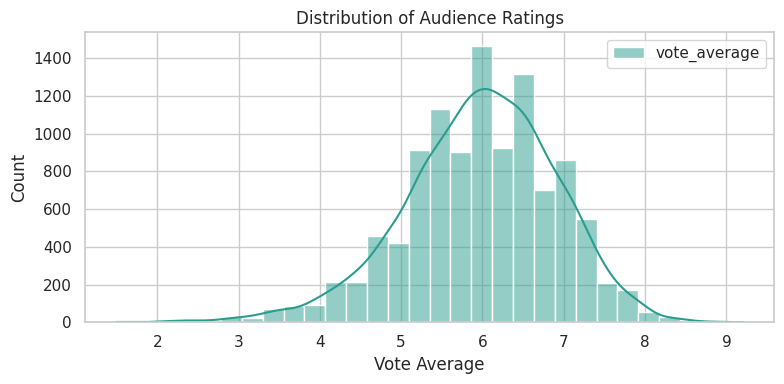

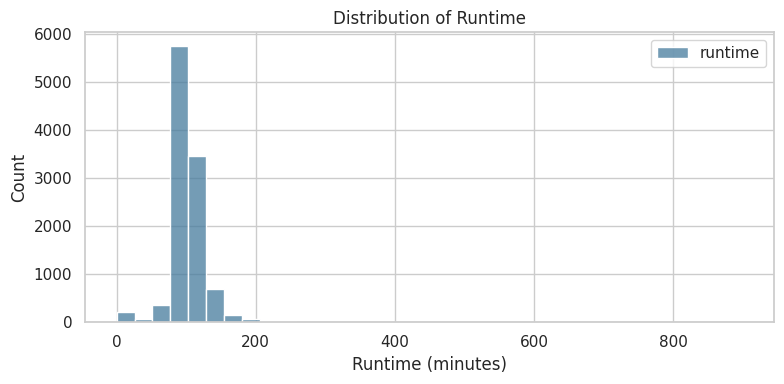

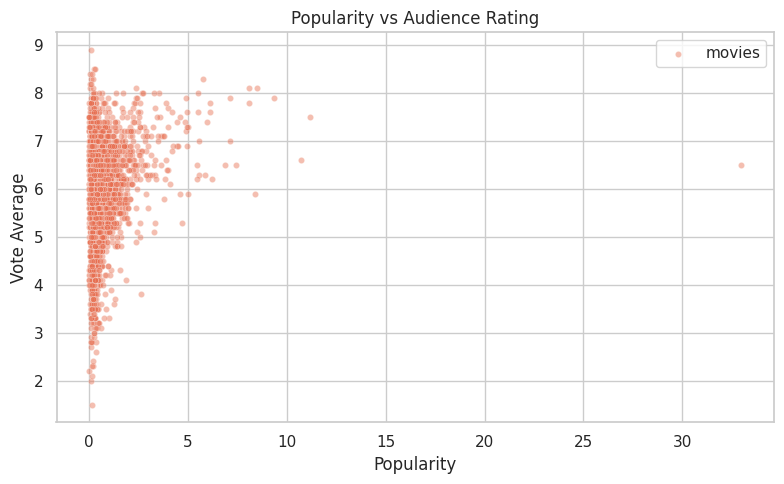

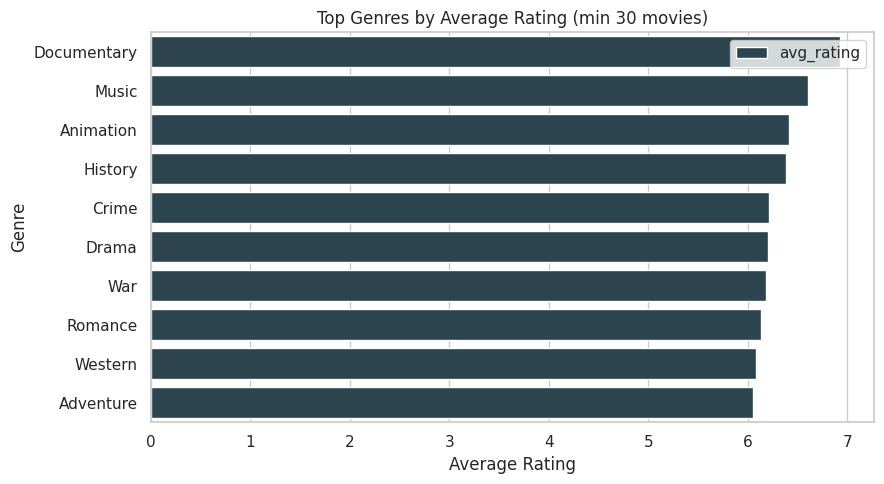

Correlation matrix (Question 1 variables):


,vote_average,runtime,popularity,vote_count
vote_average,1.00,0.16,0.21,0.25
runtime,0.16,1.00,0.14,0.16
popularity,0.21,0.14,1.00,0.80
vote_count,0.25,0.16,0.80,1.00


Permutation test (high vs low popularity rating means): diff=0.380, p-value=0.0000


In [4]:
def plot_with_labels(title, xlabel, ylabel, legend=True):
    """Apply consistent labels and layout to reduce repetitive plotting code."""
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    if legend:
        plt.legend()
    plt.tight_layout()

def permutation_test_mean_diff(a, b, n_perm=2000):
    """Two-sided permutation test for difference in means: mean(a) - mean(b)."""
    a = np.asarray(a)
    b = np.asarray(b)
    observed = a.mean() - b.mean()
    pooled = np.concatenate([a, b])
    n_a = len(a)
    diffs = np.empty(n_perm)

    for i in range(n_perm):
        perm = np.random.permutation(pooled)
        diffs[i] = perm[:n_a].mean() - perm[n_a:].mean()

    p_value = np.mean(np.abs(diffs) >= np.abs(observed))
    return observed, p_value

# 1D: distribution of vote average
plt.figure(figsize=(8, 4))
sns.histplot(df_clean['vote_average'], bins=30, kde=True, color='#2a9d8f', label='vote_average')
plot_with_labels('Distribution of Audience Ratings', 'Vote Average', 'Count')
plt.show()

# 1D: runtime distribution
plt.figure(figsize=(8, 4))
sns.histplot(df_clean['runtime'], bins=35, color='#457b9d', label='runtime')
plot_with_labels('Distribution of Runtime', 'Runtime (minutes)', 'Count')
plt.show()

# 2D: popularity vs rating
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_clean.sample(min(3000, len(df_clean)), random_state=42),
    x='popularity', y='vote_average', alpha=0.45, s=20, color='#e76f51', label='movies'
)
plot_with_labels('Popularity vs Audience Rating', 'Popularity', 'Vote Average')
plt.show()

# 2D: top genres by average rating
genre_rating = (
    df_clean.groupby('primary_genre', as_index=False)['vote_average']
    .agg(['mean', 'count'])
    .reset_index()
    .rename(columns={'mean': 'avg_rating', 'count': 'n_movies'})
)
genre_rating = genre_rating[genre_rating['n_movies'] >= 30].sort_values('avg_rating', ascending=False).head(10)

plt.figure(figsize=(9, 5))
sns.barplot(data=genre_rating, x='avg_rating', y='primary_genre', color='#264653', label='avg_rating')
plot_with_labels('Top Genres by Average Rating (min 30 movies)', 'Average Rating', 'Genre')
plt.show()

# Statistical summary for question 1
corr_q1 = df_clean[['vote_average', 'runtime', 'popularity', 'vote_count']].corr(numeric_only=True)
print('Correlation matrix (Question 1 variables):')
display(corr_q1)

high_pop = df_clean[df_clean['popularity'] >= df_clean['popularity'].quantile(0.75)]['vote_average']
low_pop = df_clean[df_clean['popularity'] <= df_clean['popularity'].quantile(0.25)]['vote_average']
obs_diff, p_val = permutation_test_mean_diff(high_pop, low_pop, n_perm=2000)
print(f'Permutation test (high vs low popularity rating means): diff={obs_diff:.3f}, p-value={p_val:.4f}')

### Interpretation (Question 1)
- The rating distribution is concentrated in the mid-to-high range, while runtime is broadly spread.
- Popularity shows a positive association with `vote_average`, but this is moderate rather than deterministic.
- Genre averages differ after minimum sample filtering, suggesting category-level variation in audience reception.
- The permutation test indicates the high-popularity and low-popularity groups have different mean ratings in this sample, supporting an association (not causation).

### Research Question 2
**Which factors are associated with higher adjusted revenue (`revenue_adj`)?**

We examine budget, popularity, and release period (decade), then summarize patterns with both visualization and statistics.

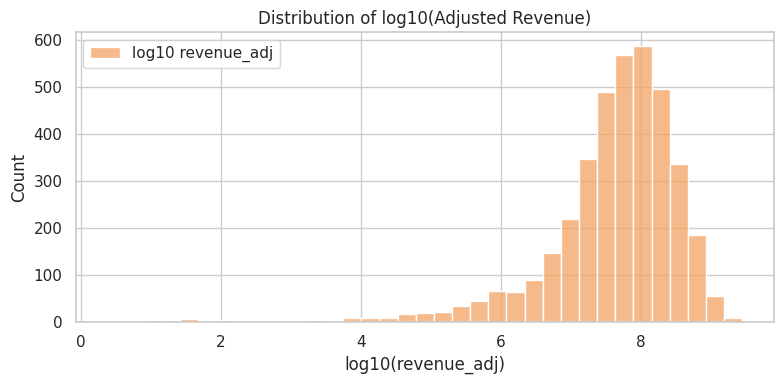

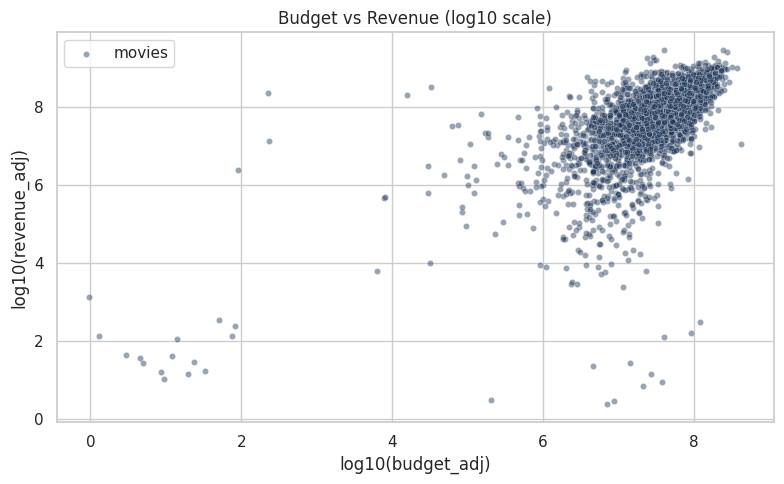

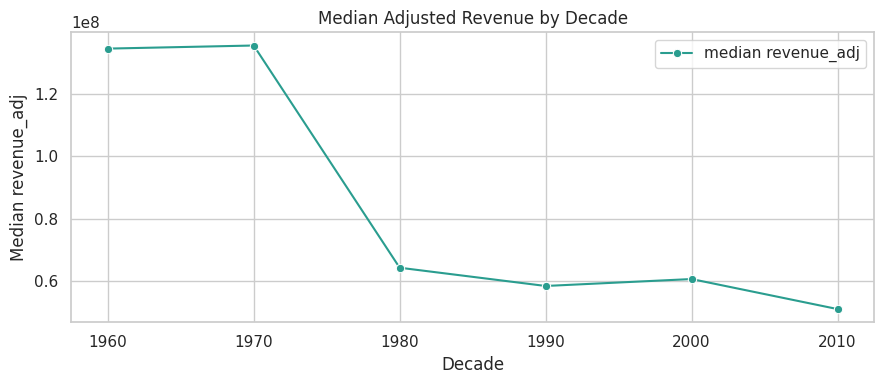

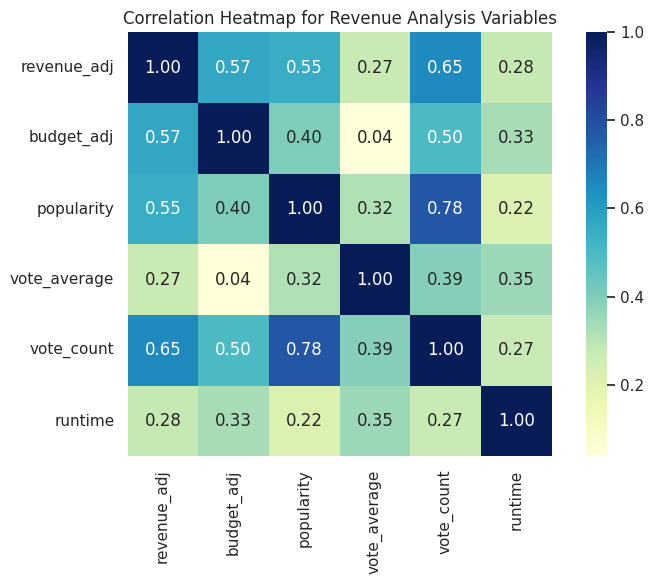

Statistical summary for key revenue-analysis variables:


,mean,50%,std,min,max
revenue_adj,"137,064,690.30","61,730,679.08","216,111,351.44",2.37,"2,827,123,750.41"
budget_adj,"44,239,993.08","30,016,111.91","44,809,254.03",0.97,"425,000,000.00"
popularity,1.19,0.80,1.48,0.00,32.99
vote_average,6.17,6.20,0.79,2.20,8.40
vote_count,527.72,204.00,879.96,10.00,"9,767.00"
runtime,109.22,106.00,19.92,15.00,338.00


In [5]:
# Build a numeric-only frame and strip non-finite values to prevent plotting/type errors
num_cols = ['revenue_adj', 'budget_adj', 'popularity', 'vote_average', 'vote_count', 'runtime']
df_money_num = df_money.copy()
for c in num_cols + ['decade'] if 'decade' in df_money.columns else num_cols:
    df_money_num[c] = pd.to_numeric(df_money_num[c], errors='coerce')
df_money_num = df_money_num.replace([np.inf, -np.inf], np.nan)

# 1D: revenue distribution (log scale for readability)
revenue_log = np.log10(df_money_num.loc[df_money_num['revenue_adj'] > 0, 'revenue_adj'].to_numpy(dtype='float64'))
revenue_log = revenue_log[np.isfinite(revenue_log)]

plt.figure(figsize=(8, 4))
sns.histplot(revenue_log, bins=35, color='#f4a261', label='log10 revenue_adj')
plot_with_labels('Distribution of log10(Adjusted Revenue)', 'log10(revenue_adj)', 'Count')
plt.show()

# 2D: budget vs revenue in log-log space
money_valid = df_money_num[(df_money_num['budget_adj'] > 0) & (df_money_num['revenue_adj'] > 0)].dropna(subset=['budget_adj', 'revenue_adj'])
sample_money = money_valid.sample(min(3000, len(money_valid)), random_state=42).copy()

x_budget = np.log10(sample_money['budget_adj'].to_numpy(dtype='float64'))
y_revenue = np.log10(sample_money['revenue_adj'].to_numpy(dtype='float64'))
valid_xy = np.isfinite(x_budget) & np.isfinite(y_revenue)
x_budget = x_budget[valid_xy]
y_revenue = y_revenue[valid_xy]

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=x_budget,
    y=y_revenue,
    alpha=0.45, s=20, color='#1d3557', label='movies'
 )
plot_with_labels('Budget vs Revenue (log10 scale)', 'log10(budget_adj)', 'log10(revenue_adj)')
plt.show()

# 2D: trend by decade
decade_revenue = (
    money_valid.groupby('decade', as_index=False)['revenue_adj']
    .median()
    .dropna()
    .sort_values('decade')
)
decade_x = decade_revenue['decade'].to_numpy(dtype='float64')
decade_y = decade_revenue['revenue_adj'].to_numpy(dtype='float64')
valid_decade = np.isfinite(decade_x) & np.isfinite(decade_y)
decade_x = decade_x[valid_decade]
decade_y = decade_y[valid_decade]

plt.figure(figsize=(9, 4))
sns.lineplot(
    x=decade_x,
    y=decade_y,
    marker='o',
    color='#2a9d8f',
    label='median revenue_adj',
    errorbar=None
)
plot_with_labels('Median Adjusted Revenue by Decade', 'Decade', 'Median revenue_adj')
plt.show()

# Heatmap-style view of numeric relationships
corr_q2 = money_valid[num_cols].astype('float64').corr(numeric_only=True)
plt.figure(figsize=(8, 6))
sns.heatmap(corr_q2, annot=True, fmt='.2f', cmap='YlGnBu', square=True)
plt.title('Correlation Heatmap for Revenue Analysis Variables')
plt.tight_layout()
plt.show()

# Compact stats table for inference support
stats_table = money_valid[num_cols].astype('float64').describe().T[['mean', '50%', 'std', 'min', 'max']]
print('Statistical summary for key revenue-analysis variables:')
display(stats_table)

### Interpretation (Question 2)
- Adjusted revenue is highly right-skewed; the log transform makes comparisons interpretable.
- In log-log space, budget and revenue show a clear positive relationship: higher-budget films tend to earn more.
- Median revenue changes across decades, consistent with period effects and market evolution.
- Correlation and summary statistics support these patterns, but they describe association only and do not establish causal effects.

<a id='conclusions'></a>
## Conclusions, Limitation

### Main Findings
1. `vote_average` shows measurable association with popularity and vote count, while runtime has a weaker relationship.
2. Genre-level average ratings differ, with some genres consistently scoring higher on average (after minimum sample filtering).
3. `revenue_adj` is positively associated with `budget_adj` and popularity, especially visible in log-scaled comparisons.
4. Median adjusted revenue differs across decades, suggesting period-related market changes.

### Limitation
- This is observational data and can only support association, not causation. For example, a higher budget correlating with higher revenue does **not** prove budget alone caused that increase.
- Genre simplification uses only the first listed genre, which may reduce multi-genre nuance.
- The dataset context and collection methods may include survivorship or reporting biases.

### Additional Research
- Add external variables (marketing spend, franchise status, release season, inflation source quality) to build stronger predictive models.
- Apply robust modeling (e.g., cross-validated regression with interaction terms) and compare with non-linear methods.
- Validate findings on a more recent and independently sourced movie dataset.

In [6]:
# Final reproducibility check: key table dimensions and null counts
print('Raw rows:', len(df_raw))
print('Clean rows:', len(df_clean))
print('Money-analysis rows:', len(df_money))

null_report = df_clean[['vote_average', 'runtime', 'budget_adj', 'revenue_adj', 'primary_genre']].isna().sum()
print('\nNulls in key cleaned fields:')
display(null_report)

print('\nNotebook implementation complete: all required sections, 1D/2D analysis, varied plots, reusable functions, and documented limitations included.')

Raw rows: 10866
Clean rows: 10865
Money-analysis rows: 3854

Nulls in key cleaned fields:


vote_average     0
runtime          0
budget_adj       0
revenue_adj      0
primary_genre    0
dtype: int64


Notebook implementation complete: all required sections, 1D/2D analysis, varied plots, reusable functions, and documented limitations included.
